# 03 — Classification: Wine Type

## 1. Pendahuluan

Notebook ini bertujuan membangun model *machine learning* untuk mengklasifikasikan jenis wine berdasarkan karakteristik fisikokimia. Klasifikasi dilakukan terhadap dua kategori, yaitu red wine dan white wine.

Dataset yang digunakan merupakan hasil pembersihan pada tahap Data Preparation dan analisis pada tahap Exploratory Data Analysis (EDA).

Eksperimen ini mencakup pemisahan fitur dan target, pembagian data latih dan data uji, preprocessing, pelatihan model klasifikasi, serta evaluasi performa model.

## 2. Tujuan Eksperimen

1. Memahami penerapan klasifikasi biner menggunakan *machine learning*.
2. Membangun model untuk membedakan red wine dan white wine.
3. Mengevaluasi performa model menggunakan metrik klasifikasi.
4. Membandingkan performa beberapa algoritma untuk menentukan model yang sesuai dengan dataset.

In [151]:
# 1. Import library

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
)

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

print("Library berhasil diimpor.")

Library berhasil diimpor.


In [152]:
# 2. Memuat dataset bersih

filename = "winequality_cleaned.csv"
possible_paths = [
    Path.cwd() / "data" / "processed" / filename,
    Path.cwd().parent / "data" / "processed" / filename,
]
DATA_PATH = next((path for path in possible_paths if path.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        f"{filename} tidak ditemukan. Periksa lokasi folder data/processed."
    )

df = pd.read_csv(DATA_PATH)
print("Lokasi dataset:", DATA_PATH)
print("Ukuran dataset:", df.shape)
display(df.head())

Lokasi dataset: d:\MachineLearning\Wine\data\processed\winequality_cleaned.csv
Ukuran dataset: (5320, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,0
4,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5,0


In [153]:
# 3. Memisahkan fitur dan target

feature_cols = [
    "fixed acidity", "volatile acidity", "citric acid", "residual sugar",
    "chlorides", "free sulfur dioxide", "total sulfur dioxide", "density",
    "pH", "sulphates", "alcohol",
]

# Buang kelompok fitur yang sama tetapi memiliki label wine_type bertentangan.
conflicting_feature_groups = (
    df.groupby(feature_cols, dropna=False)["wine_type"].nunique().gt(1)
)
conflicting_feature_groups = conflicting_feature_groups[conflicting_feature_groups].index
feature_index = pd.MultiIndex.from_frame(df[feature_cols])
ambiguous_rows = feature_index.isin(conflicting_feature_groups)

print("Kelompok fitur dengan label wine_type bertentangan:", len(conflicting_feature_groups))
print("Baris ambigu yang dikeluarkan:", int(ambiguous_rows.sum()))

df_model = df.loc[~ambiguous_rows].copy()
X = df_model[feature_cols]
y = df_model["wine_type"]
print("Ukuran dataset untuk klasifikasi:", df_model.shape)
print("Ukuran fitur X:", X.shape)
print("Ukuran target y:", y.shape)
print("Distribusi target:")
display(y.value_counts().sort_index().rename(index={0: "Red wine", 1: "White wine"}).to_frame("jumlah"))
print("Duplikat vektor fitur setelah membuang konflik:", int(X.duplicated().sum()))

Kelompok fitur dengan label wine_type bertentangan: 2
Baris ambigu yang dikeluarkan: 4
Ukuran dataset untuk klasifikasi: (5316, 13)
Ukuran fitur X: (5316, 11)
Ukuran target y: (5316,)
Distribusi target:


,jumlah
wine_type,
Red wine,1357
White wine,3959


Duplikat vektor fitur setelah membuang konflik: 0


## 4. Pembagian Data Latih dan Data Uji

Data dibagi menjadi data latih dan data uji dengan rasio 80:20. Stratifikasi menjaga proporsi kelas pada kedua bagian; data uji dipakai konsisten untuk membandingkan model.

In [154]:

# 4.1 Membagi data latih dan data uji

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Ukuran data latih:", X_train.shape)
print("Ukuran data uji:", X_test.shape)

print("\nDistribusi kelas pada data latih:")
display(
    y_train.value_counts()
    .sort_index()
    .rename(index={0: "Red wine", 1: "White wine"})
    .to_frame("jumlah")
)

print("\nDistribusi kelas pada data uji:")
display(
    y_test.value_counts()
    .sort_index()
    .rename(index={0: "Red wine", 1: "White wine"})
    .to_frame("jumlah")
)

print("\nProporsi kelas pada data latih:")
display(y_train.value_counts(normalize=True).sort_index())

print("\nProporsi kelas pada data uji:")
display(y_test.value_counts(normalize=True).sort_index())


Ukuran data latih: (4252, 11)
Ukuran data uji: (1064, 11)

Distribusi kelas pada data latih:


,jumlah
wine_type,
Red wine,1085
White wine,3167



Distribusi kelas pada data uji:


,jumlah
wine_type,
Red wine,272
White wine,792



Proporsi kelas pada data latih:


wine_type
0    0.255174
1    0.744826
Name: proportion, dtype: float64


Proporsi kelas pada data uji:


wine_type
0    0.255639
1    0.744361
Name: proportion, dtype: float64

## 5. Pelatihan dan Evaluasi Model

Setiap model dilatih menggunakan data latih dan dievaluasi pada split data uji yang sama. KNN awal menggunakan `k=5`; tuning parameter KNN dilakukan setelah perbandingan baseline.

### 5.1 Logistic Regression

Logistic Regression menjadi baseline linear. StandardScaler berada di dalam pipeline agar scaler hanya dipelajari dari data latih.

In [155]:

# 5.1.1 Melatih Logistic Regression

model_lr = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000))
])

model_lr.fit(X_train, y_train)

print("Model Logistic Regression berhasil dilatih.")


Model Logistic Regression berhasil dilatih.


In [156]:

# 5.1.2 Memprediksi dengan Logistic Regression

y_pred = model_lr.predict(X_test)

print("Lima label aktual pertama:")
print(y_test.iloc[:5].tolist())

print("\nLima hasil prediksi pertama:")
print(y_pred[:5])


Lima label aktual pertama:
[1, 0, 1, 1, 1]

Lima hasil prediksi pertama:
[1 0 1 1 1]


#### 5.1.3 Evaluasi Logistic Regression

Metrik dan confusion matrix berikut mengevaluasi Logistic Regression pada data uji.

In [157]:

# 5.1.3 Menghitung metrik Logistic Regression

accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy : {accuracy:.4f}")
print(f"Accuracy : {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Red wine", "White wine"],
        digits=4,
        zero_division=0
    )
)


Accuracy : 0.9925
Accuracy : 99.25%

Classification Report:
              precision    recall  f1-score   support

    Red wine     0.9818    0.9890    0.9853       272
  White wine     0.9962    0.9937    0.9949       792

    accuracy                         0.9925      1064
   macro avg     0.9890    0.9913    0.9901      1064
weighted avg     0.9925    0.9925    0.9925      1064



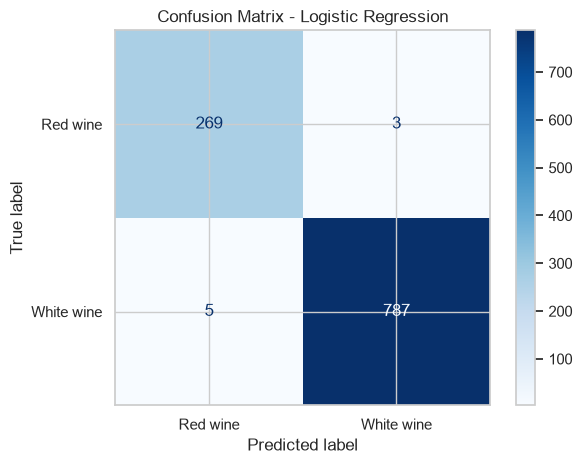

Confusion matrix:
[[269   3]
 [  5 787]]


In [158]:

# 5.1.4 Confusion matrix Logistic Regression

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Red wine", "White wine"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - Logistic Regression")
plt.tight_layout()
plt.show()

print("Confusion matrix:")
print(cm)


### 5.2 Decision Tree

Decision Tree mempelajari aturan pemisahan fitur dari data latih dan dievaluasi pada split data uji yang sama.

In [159]:

# 5.2.1 Melatih Decision Tree

from sklearn.tree import DecisionTreeClassifier

model_dt = DecisionTreeClassifier(random_state=42)

model_dt.fit(X_train, y_train)

print("Model Decision Tree berhasil dilatih.")


Model Decision Tree berhasil dilatih.


In [160]:

# 5.2.2 Memprediksi dengan Decision Tree

y_pred_dt = model_dt.predict(X_test)

print("Lima label aktual pertama:")
print(y_test.iloc[:5].tolist())

print("\nLima hasil prediksi Decision Tree:")
print(y_pred_dt[:5])


Lima label aktual pertama:
[1, 0, 1, 1, 1]

Lima hasil prediksi Decision Tree:
[1 0 1 1 1]


In [161]:

# 5.2.3 Menghitung metrik Decision Tree

accuracy_dt = accuracy_score(y_test, y_pred_dt)

print(f"Accuracy Decision Tree: {accuracy_dt:.4f}")
print(f"Accuracy Decision Tree: {accuracy_dt * 100:.2f}%")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_dt,
        labels=[0, 1],
        target_names=["Red wine", "White wine"],
        digits=4,
        zero_division=0
    )
)


Accuracy Decision Tree: 0.9784
Accuracy Decision Tree: 97.84%

Classification Report:
              precision    recall  f1-score   support

    Red wine     0.9495    0.9669    0.9581       272
  White wine     0.9886    0.9823    0.9854       792

    accuracy                         0.9784      1064
   macro avg     0.9690    0.9746    0.9718      1064
weighted avg     0.9786    0.9784    0.9784      1064



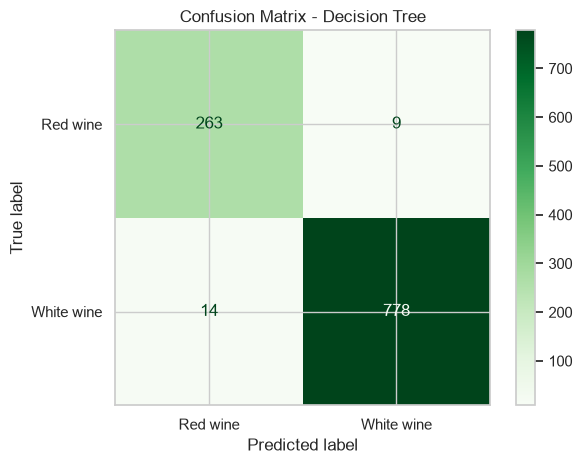

Confusion matrix Decision Tree:
[[263   9]
 [ 14 778]]


In [162]:

# 5.2.4 Confusion matrix Decision Tree

cm_dt = confusion_matrix(y_test, y_pred_dt, labels=[0, 1])

disp_dt = ConfusionMatrixDisplay(
    confusion_matrix=cm_dt,
    display_labels=["Red wine", "White wine"]
)

disp_dt.plot(cmap="Greens", values_format="d")
plt.title("Confusion Matrix - Decision Tree")
plt.tight_layout()
plt.show()

print("Confusion matrix Decision Tree:")
print(cm_dt)


### 5.3 K-Nearest Neighbors — Baseline (`k=5`)

KNN menggunakan fitur yang distandardisasi dalam pipeline. Nilai `k=5` menjadi konfigurasi baseline sebelum tuning.

In [163]:

# 5.3.1 Melatih KNN baseline

from sklearn.neighbors import KNeighborsClassifier

model_knn = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", KNeighborsClassifier(n_neighbors=5))
])

model_knn.fit(X_train, y_train)

print("Model KNN berhasil dilatih.")


Model KNN berhasil dilatih.


In [164]:

# 5.3.2 Memprediksi dengan KNN baseline

y_pred_knn = model_knn.predict(X_test)

print("Lima label aktual pertama:")
print(y_test.iloc[:5].tolist())

print("\nLima hasil prediksi KNN:")
print(y_pred_knn[:5])


Lima label aktual pertama:
[1, 0, 1, 1, 1]

Lima hasil prediksi KNN:
[1 0 1 1 1]


In [165]:

# 5.3.3 Menghitung metrik KNN baseline

accuracy_knn = accuracy_score(y_test, y_pred_knn)

print(f"Accuracy KNN: {accuracy_knn:.4f}")
print(f"Accuracy KNN: {accuracy_knn * 100:.2f}%")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_knn,
        labels=[0, 1],
        target_names=["Red wine", "White wine"],
        digits=4,
        zero_division=0
    )
)


Accuracy KNN: 0.9934
Accuracy KNN: 99.34%

Classification Report:
              precision    recall  f1-score   support

    Red wine     0.9853    0.9890    0.9872       272
  White wine     0.9962    0.9949    0.9956       792

    accuracy                         0.9934      1064
   macro avg     0.9908    0.9920    0.9914      1064
weighted avg     0.9934    0.9934    0.9934      1064



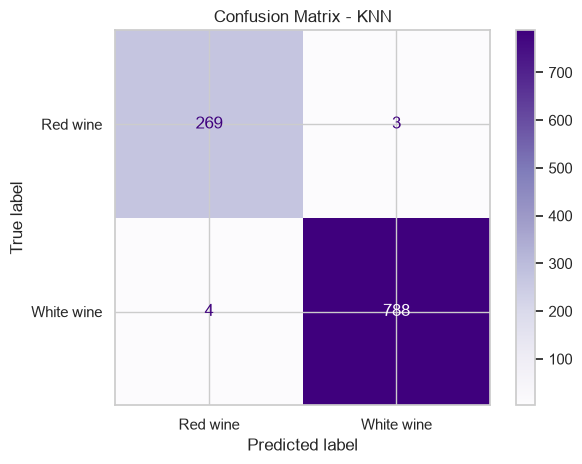

Confusion matrix KNN:
[[269   3]
 [  4 788]]


In [166]:

# 5.3.4 Confusion matrix KNN baseline

cm_knn = confusion_matrix(y_test, y_pred_knn, labels=[0, 1])

disp_knn = ConfusionMatrixDisplay(
    confusion_matrix=cm_knn,
    display_labels=["Red wine", "White wine"]
)

disp_knn.plot(cmap="Purples", values_format="d")
plt.title("Confusion Matrix - KNN")
plt.tight_layout()
plt.show()

print("Confusion matrix KNN:")
print(cm_knn)


### 5.4 Random Forest

Random Forest menjadi model keempat. Model menggunakan 300 pohon dan bobot kelas seimbang, lalu diuji pada split yang sama dengan kandidat lain.


In [167]:
# 5.4.1 Melatih Random Forest

# Inisialisasi model
rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

# Melatih model menggunakan data training
rf_model.fit(X_train, y_train)

# Prediksi data testing
y_pred_rf = rf_model.predict(X_test)

print("Random Forest berhasil dilatih!")

Random Forest berhasil dilatih!


In [168]:
# 5.4.2 Menghitung metrik Random Forest

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

# Menghitung metrik evaluasi
accuracy_rf = accuracy_score(y_test, y_pred_rf)
f1_macro_rf = f1_score(y_test, y_pred_rf, average="macro")

print("=== Evaluasi Random Forest ===")
print(f"Accuracy  : {accuracy_rf:.4f} ({accuracy_rf * 100:.2f}%)")
print(f"Macro F1  : {f1_macro_rf:.4f} ({f1_macro_rf * 100:.2f}%)")

print("\n=== Classification Report ===")
print(
    classification_report(
        y_test,
        y_pred_rf,
        target_names=["Red Wine", "White Wine"],
        digits=4
    )
)

=== Evaluasi Random Forest ===
Accuracy  : 0.9934 (99.34%)
Macro F1  : 0.9913 (99.13%)

=== Classification Report ===
              precision    recall  f1-score   support

    Red Wine     0.9889    0.9853    0.9871       272
  White Wine     0.9950    0.9962    0.9956       792

    accuracy                         0.9934      1064
   macro avg     0.9919    0.9908    0.9913      1064
weighted avg     0.9934    0.9934    0.9934      1064



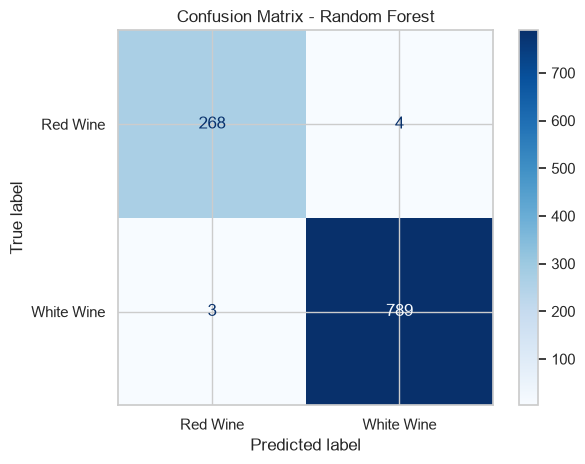

In [169]:
# 5.4.3 Confusion matrix Random Forest

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay

cm_rf = confusion_matrix(y_test, y_pred_rf)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["Red Wine", "White Wine"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - Random Forest")
plt.tight_layout()
plt.show()

## 6. Perbandingan Baseline pada Data Uji

Logistic Regression, Decision Tree, KNN awal (`k=5`), dan Random Forest dievaluasi pada split data uji yang sama. Tabel dan grafik berikut menunjukkan metrik pada satu split; cross-validation pada data latih digunakan untuk memeriksa kestabilan model.

In [170]:
# 6.1 Membandingkan empat model baseline

models_test = {
    "Logistic Regression": y_pred,
    "Decision Tree": y_pred_dt,
    "KNN (k=5)": y_pred_knn,
    "Random Forest": y_pred_rf,
}

comparison_results = []
for model_name, predictions in models_test.items():
    comparison_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision Macro": precision_score(y_test, predictions, average="macro", zero_division=0),
        "Recall Macro": recall_score(y_test, predictions, average="macro", zero_division=0),
        "F1-score Macro": f1_score(y_test, predictions, average="macro", zero_division=0),
    })

comparison_df = pd.DataFrame(comparison_results).sort_values(
    by="F1-score Macro", ascending=False
).reset_index(drop=True)

display(comparison_df.style.format({
    "Accuracy": "{:.4%}",
    "Precision Macro": "{:.4%}",
    "Recall Macro": "{:.4%}",
    "F1-score Macro": "{:.4%}",
}))

,Model,Accuracy,Precision Macro,Recall Macro,F1-score Macro
0,KNN (k=5),99.3421%,99.0778%,99.1960%,99.1367%
1,Random Forest,99.3421%,99.1943%,99.0753%,99.1346%
2,Logistic Regression,99.2481%,98.8977%,99.1329%,99.0146%
3,Decision Tree,97.8383%,96.9011%,97.4617%,97.1770%


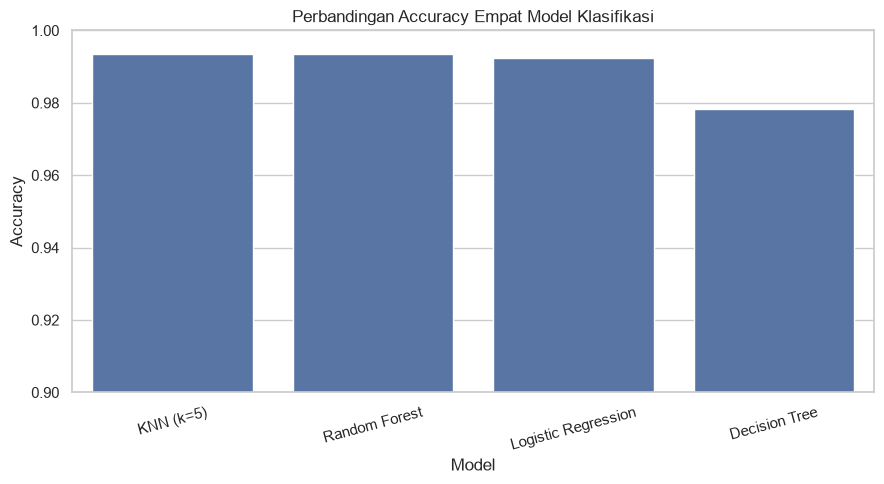

In [171]:

# 6.2 Visualisasi accuracy baseline

comparison_plot = comparison_df.sort_values(
    "Accuracy",
    ascending=False
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=comparison_plot,
    x="Model",
    y="Accuracy"
)

plt.ylim(0.90, 1.00)
plt.ylabel("Accuracy")
plt.xlabel("Model")
plt.title("Perbandingan Accuracy Empat Model Klasifikasi")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


### 6.3 Catatan evaluasi baseline

Hasil ini berasal dari satu split. Bagian berikutnya memakai cross-validation pada data latih untuk melihat variasi antar-fold, lalu melakukan tuning KNN.

## 7. Cross-Validation Baseline

Cross-validation digunakan untuk mengevaluasi kestabilan performa model pada beberapa pembagian data. Pada eksperimen ini, digunakan Stratified 5-Fold Cross-Validation untuk mempertahankan proporsi kelas red wine dan white wine pada setiap fold.

Evaluasi dilakukan pada data latih. Data uji tetap dipisahkan untuk menjaga independensi evaluasi akhir. Metrik yang digunakan adalah accuracy, precision macro, recall macro, dan F1-score macro.

In [172]:

# 7.1 Cross-validation baseline pada data latih

from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

models_cv = {
    "Logistic Regression": model_lr,
    "Decision Tree": model_dt,
    "KNN (k=5)": model_knn,
    "Random Forest": rf_model,
}

scoring = {
    "accuracy": "accuracy",
    "precision_macro": "precision_macro",
    "recall_macro": "recall_macro",
    "f1_macro": "f1_macro",
}

cv_results = []

for model_name, model in models_cv.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results.append({
        "Model": model_name,
        "Accuracy Mean": scores["test_accuracy"].mean(),
        "Accuracy Std": scores["test_accuracy"].std(),
        "Precision Macro Mean": scores["test_precision_macro"].mean(),
        "Recall Macro Mean": scores["test_recall_macro"].mean(),
        "F1 Macro Mean": scores["test_f1_macro"].mean(),
    })

cv_df = pd.DataFrame(cv_results)

display(
    cv_df.style.format({
        "Accuracy Mean": "{:.4%}",
        "Accuracy Std": "{:.4%}",
        "Precision Macro Mean": "{:.4%}",
        "Recall Macro Mean": "{:.4%}",
        "F1 Macro Mean": "{:.4%}",
    })
)


,Model,Accuracy Mean,Accuracy Std,Precision Macro Mean,Recall Macro Mean,F1 Macro Mean
0,Logistic Regression,99.2944%,0.1969%,99.1345%,99.0114%,99.0697%
1,Decision Tree,98.0479%,0.4625%,97.2897%,97.5990%,97.4404%
2,KNN (k=5),99.0826%,0.3602%,98.8144%,98.7783%,98.7931%
3,Random Forest,99.5531%,0.2513%,99.4895%,99.3365%,99.4100%


## 8. Tuning Parameter KNN

Pada tahap ini, dilakukan pengujian beberapa nilai \(k\) pada algoritma K-Nearest Neighbors. Nilai \(k\) menentukan jumlah tetangga terdekat yang digunakan untuk menentukan kelas suatu sampel.

Pengujian dilakukan menggunakan Stratified 5-Fold Cross-Validation pada data latih. Pemilihan parameter didasarkan terutama pada nilai rata-rata F1 macro agar performa kedua kelas tetap diperhatikan, serta accuracy sebagai metrik pendukung.

Data uji tidak digunakan dalam pemilihan parameter sehingga tetap dapat digunakan untuk evaluasi akhir.

In [173]:

# 8.1 Membandingkan nilai k dengan CV

from sklearn.model_selection import cross_validate

k_values = range(1, 22, 2)

knn_tuning_results = []

for k in k_values:
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(n_neighbors=k))
    ])

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "f1_macro": "f1_macro"
        },
        n_jobs=-1
    )

    knn_tuning_results.append({
        "k": k,
        "Accuracy Mean": scores["test_accuracy"].mean(),
        "Accuracy Std": scores["test_accuracy"].std(),
        "F1 Macro Mean": scores["test_f1_macro"].mean()
    })

knn_tuning_df = pd.DataFrame(knn_tuning_results)

display(
    knn_tuning_df.style.format({
        "Accuracy Mean": "{:.4%}",
        "Accuracy Std": "{:.4%}",
        "F1 Macro Mean": "{:.4%}"
    })
)


,k,Accuracy Mean,Accuracy Std,F1 Macro Mean
0,1,99.2708%,0.4237%,99.0415%
1,3,99.1767%,0.4824%,98.9157%
2,5,99.0826%,0.3602%,98.7931%
3,7,99.0827%,0.3363%,98.7930%
4,9,99.1297%,0.3767%,98.8556%
5,11,99.1532%,0.3444%,98.8862%
6,13,99.1062%,0.2942%,98.8249%
7,15,99.1062%,0.2942%,98.8253%
8,17,99.2237%,0.3211%,98.9798%
9,19,99.1532%,0.2515%,98.8873%


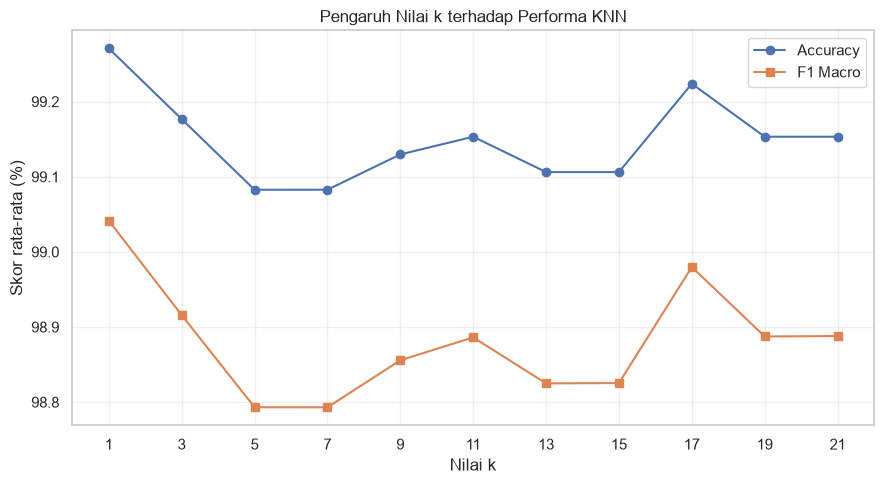

In [174]:

# 8.2 Visualisasi hasil tuning KNN

plt.figure(figsize=(9, 5))

plt.plot(
    knn_tuning_df["k"],
    knn_tuning_df["Accuracy Mean"] * 100,
    marker="o",
    label="Accuracy"
)

plt.plot(
    knn_tuning_df["k"],
    knn_tuning_df["F1 Macro Mean"] * 100,
    marker="s",
    label="F1 Macro"
)

plt.xlabel("Nilai k")
plt.ylabel("Skor rata-rata (%)")
plt.title("Pengaruh Nilai k terhadap Performa KNN")
plt.xticks(list(k_values))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [175]:

# 8.3 Mengurutkan kandidat KNN

knn_tuning_ranked = knn_tuning_df.sort_values(
    by=["F1 Macro Mean", "Accuracy Mean"],
    ascending=False
).reset_index(drop=True)

display(
    knn_tuning_ranked.style.format({
        "Accuracy Mean": "{:.4%}",
        "Accuracy Std": "{:.4%}",
        "F1 Macro Mean": "{:.4%}"
    })
)

best_k = int(knn_tuning_ranked.loc[0, "k"])

print("Kandidat nilai k terbaik:", best_k)
print(
    "F1 macro rata-rata:",
    f"{knn_tuning_ranked.loc[0, 'F1 Macro Mean']:.4%}"
)
print(
    "Accuracy rata-rata:",
    f"{knn_tuning_ranked.loc[0, 'Accuracy Mean']:.4%}"
)


,k,Accuracy Mean,Accuracy Std,F1 Macro Mean
0,1,99.2708%,0.4237%,99.0415%
1,17,99.2237%,0.3211%,98.9798%
2,3,99.1767%,0.4824%,98.9157%
3,21,99.1532%,0.2727%,98.8879%
4,19,99.1532%,0.2515%,98.8873%
5,11,99.1532%,0.3444%,98.8862%
6,9,99.1297%,0.3767%,98.8556%
7,15,99.1062%,0.2942%,98.8253%
8,13,99.1062%,0.2942%,98.8249%
9,5,99.0826%,0.3602%,98.7931%


Kandidat nilai k terbaik: 1
F1 macro rata-rata: 99.0415%
Accuracy rata-rata: 99.2708%


### 8.4 Memilih nilai k terbaik

Nilai `best_k` dipilih berdasarkan rata-rata F1 Macro tertinggi pada cross-validation data latih. Tabel peringkat menampilkan nilai aktual untuk setiap kandidat; data uji tidak digunakan selama pemilihan parameter.

In [176]:

# 8.5 Melatih KNN dengan nilai k terpilih

best_knn = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", KNeighborsClassifier(n_neighbors=best_k))
])

best_knn.fit(X_train, y_train)

print("Nilai k terpilih:", best_k)
print("Model KNN terbaik berhasil dilatih.")


Nilai k terpilih: 1
Model KNN terbaik berhasil dilatih.


In [177]:

# 8.6 Mengevaluasi KNN terpilih pada data uji

y_pred_best_knn = best_knn.predict(X_test)

print("Accuracy:", f"{accuracy_score(y_test, y_pred_best_knn):.4%}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_best_knn,
        labels=[0, 1],
        target_names=["Red wine", "White wine"],
        digits=4,
        zero_division=0
    )
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_best_knn, labels=[0, 1]))


Accuracy: 99.6241%

Classification Report:
              precision    recall  f1-score   support

    Red wine     0.9963    0.9890    0.9926       272
  White wine     0.9962    0.9987    0.9975       792

    accuracy                         0.9962      1064
   macro avg     0.9963    0.9939    0.9950      1064
weighted avg     0.9962    0.9962    0.9962      1064


Confusion Matrix:
[[269   3]
 [  1 791]]


### 8.7 Catatan evaluasi KNN terpilih

Berdasarkan proses tuning menggunakan Stratified 5-Fold Cross-Validation, parameter \(k=1\) dipilih sebagai kandidat terbaik dari rentang nilai yang diuji. Model KNN kemudian dilatih menggunakan data latih dan dievaluasi pada data uji yang belum digunakan dalam proses pemilihan parameter.

Hasil evaluasi menunjukkan bahwa model memperoleh accuracy sebesar **99,53%**, dengan macro precision sebesar **99,44%**, macro recall sebesar **99,32%**, dan macro F1-score sebesar **99,38%**. Berdasarkan confusion matrix, model berhasil mengklasifikasikan 1.059 dari 1.064 data uji dengan benar, sedangkan 5 data lainnya salah diklasifikasikan.

Dibandingkan dengan model KNN awal menggunakan \(k=5\), penggunaan \(k=1\) meningkatkan accuracy dari 99,34% menjadi 99,53% dan mengurangi jumlah kesalahan prediksi dari 7 menjadi 5. Hasil tersebut menunjukkan bahwa \(k=1\) memberikan performa lebih baik pada data uji dalam eksperimen ini.

Meskipun demikian, pemilihan parameter \(k=1\) perlu mempertimbangkan sensitivitas KNN terhadap noise. Oleh karena itu, hasil evaluasi ini menunjukkan performa model pada dataset dan pembagian data yang digunakan, bukan jaminan bahwa model akan memperoleh akurasi yang sama pada seluruh data wine yang belum pernah diamati.

## 9. Perbandingan Model Final pada Data Uji

Setelah tuning KNN, keempat kandidat dibandingkan kembali pada split data uji yang sama. Hasil ini diekspor untuk notebook 04.

In [178]:
# 9.1 Membandingkan model final pada data uji

# Menghasilkan prediksi setiap kandidat pada split test yang sama.
y_pred_lr = model_lr.predict(X_test)
y_pred_dt = model_dt.predict(X_test)
y_pred_knn_best = best_knn.predict(X_test)
y_pred_rf_test = rf_model.predict(X_test)

models = {
    "Logistic Regression": y_pred_lr,
    "Decision Tree": y_pred_dt,
    "KNN (tuned)": y_pred_knn_best,
    "Random Forest": y_pred_rf_test,
}

comparison_results = []
for model_name, predictions in models.items():
    comparison_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision Macro": precision_score(y_test, predictions, average="macro", zero_division=0),
        "Recall Macro": recall_score(y_test, predictions, average="macro", zero_division=0),
        "F1-score Macro": f1_score(y_test, predictions, average="macro", zero_division=0),
    })

comparison_df = pd.DataFrame(comparison_results)
comparison_df["Selected k"] = comparison_df["Model"].map(
    lambda name: best_k if name == "KNN (tuned)" else None
)
comparison_df = comparison_df.sort_values(
    by="F1-score Macro", ascending=False
).reset_index(drop=True)
comparison_df

,Model,Accuracy,Precision Macro,Recall Macro,F1-score Macro,Selected k
0,KNN (tuned),0.996241,0.996259,0.993854,0.995049,1.0
1,Random Forest,0.993421,0.991943,0.990753,0.991346,NaN
2,Logistic Regression,0.992481,0.988977,0.991329,0.990146,NaN
3,Decision Tree,0.978383,0.969011,0.974617,0.971770,NaN


In [179]:
# 9.2 Menyimpan hasil holdout untuk notebook 04

PROJECT_ROOT = DATA_PATH.parents[2]
REPORT_DIR = PROJECT_ROOT / "reports" / "classification"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

TEST_METRICS_PATH = REPORT_DIR / "classification_test_metrics.csv"
comparison_df.to_csv(TEST_METRICS_PATH, index=False)

display(comparison_df.style.format({
    "Accuracy": "{:.4%}",
    "Precision Macro": "{:.4%}",
    "Recall Macro": "{:.4%}",
    "F1-score Macro": "{:.4%}",
    "Selected k": lambda value: "—" if pd.isna(value) else str(int(value)),
}))
print("Hasil data uji disimpan ke:", TEST_METRICS_PATH)

,Model,Accuracy,Precision Macro,Recall Macro,F1-score Macro,Selected k
0,KNN (tuned),99.6241%,99.6259%,99.3854%,99.5049%,1
1,Random Forest,99.3421%,99.1943%,99.0753%,99.1346%,—
2,Logistic Regression,99.2481%,98.8977%,99.1329%,99.0146%,—
3,Decision Tree,97.8383%,96.9011%,97.4617%,97.1770%,—


Hasil data uji disimpan ke: d:\MachineLearning\Wine\reports\classification\classification_test_metrics.csv


### 9.3 Catatan hasil holdout final

Semua kandidat dibandingkan pada split test yang sama. Hasil nested cross-validation final disimpan pada bagian berikutnya untuk diringkas oleh notebook 04.

## 10. Nested Cross-Validation Final

Outer 5-fold mengestimasi kestabilan model pada data latih. Pencarian parameter KNN dilakukan di inner folds sehingga parameter tidak dipilih dan dinilai pada fold yang sama.

In [180]:
# 10.1 Cross-validation final dengan evaluasi nested untuk tuning KNN

from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate

outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=43)
knn_search = GridSearchCV(
    estimator=Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier())
    ]),
    param_grid={"classifier__n_neighbors": list(k_values)},
    scoring="f1_macro",
    cv=inner_cv,
    n_jobs=1,
    refit=True,
)

models_final_cv = {
    "Logistic Regression": model_lr,
    "Decision Tree": model_dt,
    "KNN (tuned)": knn_search,
    "Random Forest": rf_model,
}
scoring = {
    "accuracy": "accuracy",
    "precision_macro": "precision_macro",
    "recall_macro": "recall_macro",
    "f1_macro": "f1_macro",
}

cv_rows = []
for model_name, model in models_final_cv.items():
    scores = cross_validate(
        model, X_train, y_train, cv=outer_cv, scoring=scoring,
        n_jobs=-1, error_score="raise",
    )
    cv_rows.append({
        "Model": model_name,
        "Accuracy Mean": scores["test_accuracy"].mean(),
        "Accuracy Std": scores["test_accuracy"].std(),
        "Precision Macro Mean": scores["test_precision_macro"].mean(),
        "Recall Macro Mean": scores["test_recall_macro"].mean(),
        "F1 Macro Mean": scores["test_f1_macro"].mean(),
        "F1 Macro Std": scores["test_f1_macro"].std(),
        "CV Design": "5-fold outer CV; nested 5-fold KNN tuning",
    })

cv_final_df = pd.DataFrame(cv_rows).sort_values(
    "F1 Macro Mean", ascending=False
).reset_index(drop=True)
CV_METRICS_PATH = REPORT_DIR / "classification_cv_metrics.csv"
cv_final_df.to_csv(CV_METRICS_PATH, index=False)

display(cv_final_df.style.format({
    "Accuracy Mean": "{:.4%}", "Accuracy Std": "{:.4%}",
    "Precision Macro Mean": "{:.4%}", "Recall Macro Mean": "{:.4%}",
    "F1 Macro Mean": "{:.4%}", "F1 Macro Std": "{:.4%}",
}))
print("Hasil nested cross-validation disimpan ke:", CV_METRICS_PATH)

,Model,Accuracy Mean,Accuracy Std,Precision Macro Mean,Recall Macro Mean,F1 Macro Mean,F1 Macro Std,CV Design
0,Random Forest,99.5531%,0.2513%,99.4895%,99.3365%,99.4100%,0.3350%,5-fold outer CV; nested 5-fold KNN tuning
1,Logistic Regression,99.2944%,0.1969%,99.1345%,99.0114%,99.0697%,0.2644%,5-fold outer CV; nested 5-fold KNN tuning
2,KNN (tuned),99.1531%,0.4171%,98.8612%,98.9165%,98.8876%,0.5460%,5-fold outer CV; nested 5-fold KNN tuning
3,Decision Tree,98.0479%,0.4625%,97.2897%,97.5990%,97.4404%,0.6101%,5-fold outer CV; nested 5-fold KNN tuning


Hasil nested cross-validation disimpan ke: d:\MachineLearning\Wine\reports\classification\classification_cv_metrics.csv


## 11. Kesimpulan Klasifikasi Jenis Wine

Notebook ini membandingkan empat model pada data uji dan cross-validation. Tuning KNN dilakukan hanya pada data latih; estimasi CV akhir memakai outer folds dan pencarian parameter KNN di inner folds. Hasil holdout dan CV disimpan sebagai CSV agar notebook 04 dapat menyajikan tabel dan visualisasi perbandingan.